# Campaign uplift analysis

## Summary

The saved analysis finds conversion uplift of **+0.1152 percentage points** overall.
At a 10% test audience, conversion-probability ranking yields **8.67 additional
conversions per 1,000 targeted**, compared with **7.17** for the logistic T-learner.
The paired bootstrap interval for that gap is **0.76 to 2.20 per 1,000**.

The workflow below reproduces the original analysis without changing its
sampling, model settings, ranking rules or statistical formulas. See [the findings](../reports/criteo_uplift_findings.md)
for interpretation and caveats.

## Context and methods

We compare campaign assignment with control on the Criteo uplift dataset, audit
input quality and group balance, explore segments, and evaluate four targeting
policies. The deterministic row split is 70% training, 15% validation and 15% test,
using seed 42. Models use all control training rows and a random 20% of campaign
training rows. Continuous columns are scaled; categorical columns are one-hot encoded.

### Key assumptions

- Interpreting rate differences causally assumes comparable treatment and control
  groups and independent observations. The `f3` imbalance warrants caution.
- Uplift concerns campaign assignment. Recorded exposure is a downstream outcome.
- Estimated extra conversions assume the selected audience is assigned to the
  campaign rather than control. They are not observed extra conversions or profit.
- Existing split files must match the input and seed. Change the output directory
  to regenerate data for a different source or seed.

Run with the repository's `.venv` kernel. Download instructions are in
[data/README.md](../data/README.md). Full execution reads the source CSV repeatedly
and fits models on millions of rows.

### Reproducibility verification

Every code cell was executed in order in a fresh IPython session after this
refactor. Exact comparisons with a fresh run of the original code confirmed
all 16 result tables, model coefficients and intercepts, test probabilities and
uplift scores, validation and test audience rankings, chart values, and printed
statistics, including the paired bootstrap interval. Tables and figures below
are saved from the refactored execution.


## 1. Imports and configuration

All imports, paths, feature roles, sampling settings and model parameters are
listed here. Each randomized stage starts its own generator with seed 42, as in
the original workflow. CSV chunk size and sorted partition order affect sampling
and must stay fixed when reproducing these results.

In [1]:
from math import sqrt
from pathlib import Path
from runpy import run_path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [2]:
# Support kernels started from the repository root or notebooks directory.
PROJECT_ROOT = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents]
     if (parent / "pyproject.toml").is_file()
     and (parent / "scripts" / "prepare_criteo_splits.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start the notebook from this repository or its notebooks directory.")

RAW_DATA_PATH = PROJECT_ROOT / "data/raw/criteo-research-uplift-v2.1.csv.gz"
SPLITS_DIR = PROJECT_ROOT / "data/processed/criteo_splits"
FIGURES_DIR = PROJECT_ROOT / "reports/figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_ROW_COUNT = 13_979_592
CSV_CHUNK_SIZE = 500_000
PREDICTION_BATCH_SIZE = 100_000
RANDOM_SEED = 42
BALANCE_SAMPLE_FRACTION = 0.05
TRAIN_ARM_KEEP_FRACTIONS = [(0, 1.0), (1, 0.20)]
F0_QUANTILES = 4
PRIORITY_F0_BIN = 1
TARGET_AUDIENCE_SHARE = 0.10
AUDIENCE_SHARES = [0.05, 0.10, 0.20, 0.30]
MIN_CATEGORY_FREQUENCY = 100
LOGISTIC_MAX_ITER = 500
CONFIDENCE_Z = 1.96
BOOTSTRAP_REPLICATES = 5_000
BOOTSTRAP_QUANTILES = [0.025, 0.975]

FEATURE_COLUMNS = [f"f{i}" for i in range(12)]
BINARY_COLUMNS = ["treatment", "conversion", "visit", "exposure"]
EXPECTED_COLUMNS = FEATURE_COLUMNS + BINARY_COLUMNS
CONTINUOUS_FEATURES = ["f0", "f2", "f7", "f10"]
CATEGORICAL_FEATURES = ["f1", "f3", "f4", "f5", "f6", "f8", "f9", "f11"]
MODEL_FEATURES = CONTINUOUS_FEATURES + CATEGORICAL_FEATURES
POLICY_METRIC = "extra_conversions_per_1000_targeted"
POLICY_STYLES = {
    "Random": ("#666666", "o", ":"),
    "Prioritize f0 bin 1": ("#D55E00", "s", "--"),
    "Predicted conversion": ("#0072B2", "D", "-"),
    "Logistic T-learner": ("#7A5195", "^", "-."),
}

prepare_splits = run_path(
    str(PROJECT_ROOT / "scripts/prepare_criteo_splits.py")
)["prepare_splits"]


## 2. Data loading and quality checks

Read the source in bounded chunks. The audit checks schema, missing and infinite
values, binary flags, and contradictions between treatment, exposure and outcomes.

In [3]:
if not RAW_DATA_PATH.is_file():
    raise FileNotFoundError(f"Download the dataset to {RAW_DATA_PATH}. See data/README.md.")
print(EXPECTED_COLUMNS)


['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


In [4]:
def audit_raw_data(source_path):
    """Audit all input rows without loading the full CSV into memory."""
    # 1. Check the header
    columns = pd.read_csv(source_path, nrows=0).columns.tolist()
    if len(columns) != len(EXPECTED_COLUMNS) or set(columns) != set(EXPECTED_COLUMNS):
        raise ValueError(f"Unexpected CSV columns: {columns}")

    audit = pd.DataFrame(0, index=EXPECTED_COLUMNS, columns=["missing", "infinite"])
    invalid_binary = pd.Series(0, index=BINARY_COLUMNS, dtype="int64")
    row_count = 0
    control_exposed = 0
    conversion_without_visit = 0
    # 2. Check every row. A nonnumeric value will raise a parsing error.
    for chunk in pd.read_csv(source_path, dtype="float64", chunksize=CSV_CHUNK_SIZE):
        row_count += len(chunk)
        audit["missing"] += chunk.isna().sum()
        audit["infinite"] += np.isinf(chunk).sum()

        flags = chunk[BINARY_COLUMNS]
        invalid_binary += (flags.notna() & ~flags.isin([0, 1])).sum()

        # 3. Check whether columns contradict each other
        control_exposed += (
            chunk["treatment"].eq(0) & chunk["exposure"].eq(1)
        ).sum()
        conversion_without_visit += (
            chunk["conversion"].eq(1) & chunk["visit"].eq(0)
        ).sum()

    audit["non_binary"] = invalid_binary.astype("Int64")
    return audit, row_count, len(columns), control_exposed, conversion_without_visit


In [5]:
audit, row_count, column_count, control_exposed, conversion_without_visit = audit_raw_data(RAW_DATA_PATH)
print(f"Rows: {row_count:,} (expected {EXPECTED_ROW_COUNT:,})")
print(f"Columns: {column_count} (expected {len(EXPECTED_COLUMNS)})")
print(f"\n{audit.to_string()}")
print(f"\nControl users exposed to an ad: {control_exposed:,}")
print(f"Conversions without a visit: {conversion_without_visit:,}")


Rows: 13,979,592 (expected 13,979,592)
Columns: 16 (expected 16)

            missing  infinite  non_binary
f0                0         0        <NA>
f1                0         0        <NA>
f2                0         0        <NA>
f3                0         0        <NA>
f4                0         0        <NA>
f5                0         0        <NA>
f6                0         0        <NA>
f7                0         0        <NA>
f8                0         0        <NA>
f9                0         0        <NA>
f10               0         0        <NA>
f11               0         0        <NA>
treatment         0         0           0
conversion        0         0           0
visit             0         0           0
exposure          0         0           0

Control users exposed to an ad: 0
Conversions without a visit: 0


## 3. Exploratory data analysis

### Campaign outcomes and overall uplift

Rates use each treatment arm's user count as the denominator. Confidence
intervals use the original unpooled binomial standard error and 1.96 multiplier.

In [6]:
def summarize_campaign_outcomes(source_path):
    """Aggregate outcome counts and rates by treatment arm."""
    columns = ["treatment", "visit", "conversion", "exposure"]

    counts = pd.DataFrame(
        0,
        index=pd.Index([0, 1], name="treatment"),
        columns=["users", "visits", "conversions", "ad_exposures"],
    )

    for chunk in pd.read_csv(source_path, usecols=columns, dtype="uint8", chunksize=CSV_CHUNK_SIZE):
        chunk_counts = chunk.groupby("treatment").agg(
            users=("treatment", "size"),
            visits=("visit", "sum"),
            conversions=("conversion", "sum"),
            ad_exposures=("exposure", "sum"),
        )
        counts += chunk_counts.reindex(counts.index, fill_value=0).astype("int64")

    summary = counts.copy()
    summary["user_share_pct"] = 100 * counts["users"] / counts["users"].sum()
    summary["visit_rate_pct"] = 100 * counts["visits"] / counts["users"]
    summary["conversion_rate_pct"] = 100 * counts["conversions"] / counts["users"]
    summary["exposure_rate_pct"] = 100 * counts["ad_exposures"] / counts["users"]

    summary = summary.rename(index={0: "Control", 1: "Campaign"})
    return counts, summary


In [7]:
counts, campaign_summary = summarize_campaign_outcomes(RAW_DATA_PATH)
display(campaign_summary.round(3))


,users,visits,conversions,ad_exposures,user_share_pct,visit_rate_pct,conversion_rate_pct,exposure_rate_pct
treatment,,,,,,,,
Control,2096937,80105,4063,0,15.0,3.820,0.194,0.000
Campaign,11882655,576824,36711,428212,85.0,4.854,0.309,3.604


In [8]:
def estimate_overall_uplift(counts):
    """Compute campaign-minus-control rate differences and normal intervals."""
    control = counts.loc[0]
    campaign = counts.loc[1]
    results = []

    for outcome in ["conversions", "visits"]:
        p_control = control[outcome] / control["users"]
        p_campaign = campaign[outcome] / campaign["users"]
        uplift = p_campaign - p_control

        standard_error = sqrt(
            p_control * (1 - p_control) / control["users"]
            + p_campaign * (1 - p_campaign) / campaign["users"]
        )
        margin = CONFIDENCE_Z * standard_error

        results.append({
            "outcome": outcome,
            "control_rate_pct": 100 * p_control,
            "campaign_rate_pct": 100 * p_campaign,
            "uplift_pp": 100 * uplift,
            "ci_low_pp": 100 * (uplift - margin),
            "ci_high_pp": 100 * (uplift + margin),
        })

    uplift_summary = pd.DataFrame(results).set_index("outcome")
    return uplift_summary


In [9]:
uplift_summary = estimate_overall_uplift(counts)
display(uplift_summary.round(4))


,control_rate_pct,campaign_rate_pct,uplift_pp,ci_low_pp,ci_high_pp
outcome,,,,,
conversions,0.1938,0.3089,0.1152,0.1085,0.1219
visits,3.8201,4.8543,1.0342,1.0056,1.0629


### Feature balance and distributions

The 5% sample uses the original per-chunk Bernoulli draws, not a fixed-size sample.

In [10]:
def sample_feature_balance(source_path):
    """Sample rows and compare continuous means and categorical shares."""
    columns = CONTINUOUS_FEATURES + CATEGORICAL_FEATURES + ["treatment"]

    rng = np.random.default_rng(RANDOM_SEED)

    sample = pd.concat(
        (
            chunk.loc[rng.random(len(chunk)) < BALANCE_SAMPLE_FRACTION]
            for chunk in pd.read_csv(source_path, usecols=columns, chunksize=CSV_CHUNK_SIZE)
        ),
        ignore_index=True,
    )

    control = sample.loc[sample["treatment"].eq(0), CONTINUOUS_FEATURES]
    campaign = sample.loc[sample["treatment"].eq(1), CONTINUOUS_FEATURES]

    # Express each mean gap in units of the feature's standard deviation.
    pooled_sd = np.sqrt((campaign.var() + control.var()) / 2)

    continuous_balance = pd.DataFrame({
        "control_mean": control.mean(),
        "campaign_mean": campaign.mean(),
        "abs_smd": (campaign.mean() - control.mean()).abs() / pooled_sd,
    }).sort_values("abs_smd", ascending=False)

    # Compare category shares within each treatment group.
    category_rows = []
    for feature in CATEGORICAL_FEATURES:
        shares = pd.crosstab(sample[feature], sample["treatment"], normalize="columns")
        gap_pp = 100 * (shares[1] - shares[0]).abs()

        category_rows.append({
            "feature": feature,
            "categories_seen": len(shares),
            "largest_category_gap_pp": gap_pp.max(),
        })

    categorical_balance = pd.DataFrame(category_rows).set_index("feature")
    return sample, control, campaign, continuous_balance, categorical_balance


In [11]:
sample, control_sample, campaign_sample, continuous_balance, categorical_balance = sample_feature_balance(RAW_DATA_PATH)
print(f"Sample: {len(control_sample):,} control and {len(campaign_sample):,} campaign users")
display(continuous_balance.round(4))
display(categorical_balance.sort_values("largest_category_gap_pp", ascending=False).round(4))


Sample: 104,469 control and 594,018 campaign users


,control_mean,campaign_mean,abs_smd
f7,5.0767,5.1021,0.0215
f10,5.3319,5.3339,0.0122
f2,8.4492,8.4461,0.0102
f0,19.6706,19.6206,0.0093


,categories_seen,largest_category_gap_pp
feature,,
f3,360,1.5508
f6,971,0.8927
f9,854,0.7041
f5,64,0.6544
f1,31,0.3107
f4,113,0.2983
f8,1912,0.2373
f11,60,0.1491


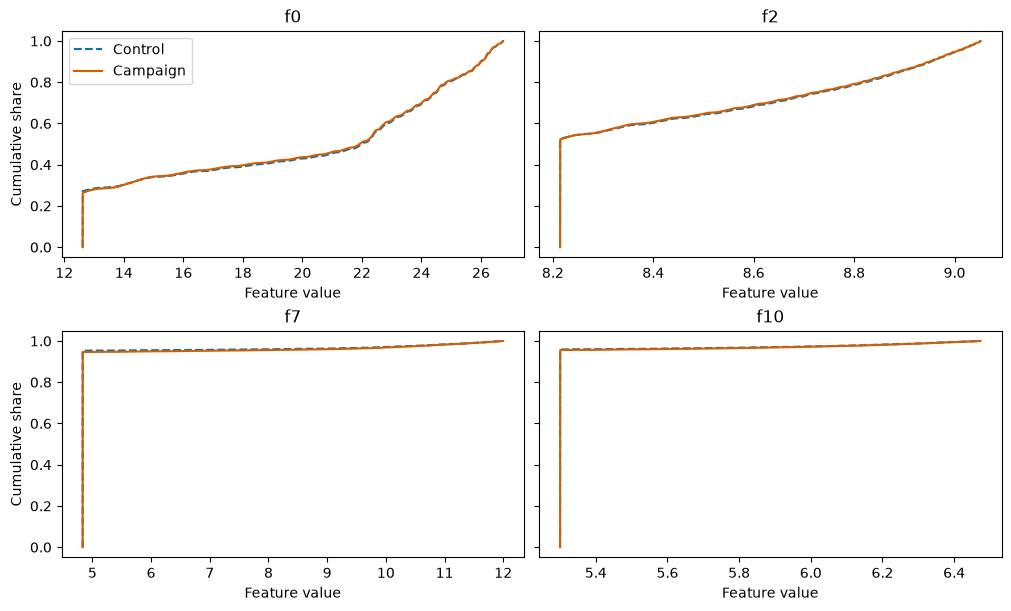

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True, layout="constrained")

for feature, ax in zip(CONTINUOUS_FEATURES, axes.flat):
    for group, label, color, line in [
        (control_sample, "Control", "#0072B2", "--"),
        (campaign_sample, "Campaign", "#D55E00", "-"),
    ]:
        values = np.sort(group[feature].to_numpy())
        cumulative_share = np.arange(1, len(values) + 1) / len(values)
        ax.step(values, cumulative_share, where="post", label=label,
                color=color, linestyle=line)

    ax.set_title(feature)
    ax.set_xlabel("Feature value")

axes[0, 0].set_ylabel("Cumulative share")
axes[1, 0].set_ylabel("Cumulative share")
axes[0, 0].legend()
plt.show()


### Full-data category imbalance and standardized uplift

In [13]:
def compare_f3_balance(source_path, sample):
    """Check the sampled f3 imbalance against the complete dataset."""
    sample_shares = pd.crosstab(
        sample["f3"], sample["treatment"], normalize="columns"
    )
    sample_gap_pp = 100 * (sample_shares[1] - sample_shares[0])

    chunk_counts = [
        chunk.groupby(["f3", "treatment"]).size()
        for chunk in pd.read_csv(source_path, usecols=["f3", "treatment"], chunksize=CSV_CHUNK_SIZE)
    ]

    f3_counts = (
        pd.concat(chunk_counts)
        .groupby(level=["f3", "treatment"]).sum()
        .unstack(fill_value=0)
    )

    # Divide by the total number of users in each group.
    full_shares = 100 * f3_counts / f3_counts.sum()

    f3_balance = pd.DataFrame({
        "control_users": f3_counts[0],
        "campaign_users": f3_counts[1],
        "control_pct": full_shares[0],
        "campaign_pct": full_shares[1],
        "sample_gap_pp": sample_gap_pp,
        "full_gap_pp": full_shares[1] - full_shares[0],
    })
    return f3_counts, f3_balance


In [14]:
f3_counts, f3_balance = compare_f3_balance(RAW_DATA_PATH, sample)
display(
    f3_balance.sort_values(
        "sample_gap_pp", key=lambda gap: gap.abs(), ascending=False
    ).head(5).round(4)
)


,control_users,campaign_users,control_pct,campaign_pct,sample_gap_pp,full_gap_pp
f3,,,,,,
4.679882,1741185,9702810,83.0347,81.6552,-1.5508,-1.3794
2.293959,17777,105861,0.8478,0.8909,0.1349,0.0431
2.587543,23103,138662,1.1017,1.1669,0.1055,0.0652
2.039645,14428,88292,0.6881,0.7430,0.0818,0.0550
3.359763,45339,263727,2.1622,2.2194,0.0635,0.0573


In [15]:
def standardize_f3_uplift(source_path, f3_counts):
    """Weight the two f3 segment uplifts by their full-population shares."""
    common_f3 = f3_counts.sum(axis=1).idxmax()
    partials = []

    for chunk in pd.read_csv(
        source_path, usecols=["f3", "treatment", "conversion"], chunksize=CSV_CHUNK_SIZE
    ):
        chunk["f3_group"] = np.where(
            chunk["f3"].eq(common_f3),
            "Most common category",
            "All other categories",
        )
        partials.append(
            chunk.groupby(["f3_group", "treatment"]).agg(
                users=("conversion", "size"),
                conversions=("conversion", "sum"),
            )
        )

    segment_counts = pd.concat(partials).groupby(level=["f3_group", "treatment"]).sum()
    rates = (segment_counts["conversions"] / segment_counts["users"]).unstack()

    segment_sizes = segment_counts["users"].groupby(level="f3_group").sum()
    weights = segment_sizes / segment_sizes.sum()
    uplift_pp = 100 * (rates[1] - rates[0])

    segment_summary = pd.DataFrame({
        "control_rate_pct": 100 * rates[0],
        "campaign_rate_pct": 100 * rates[1],
        "uplift_pp": uplift_pp,
        "weight_pct": 100 * weights,
    })
    return segment_summary, (weights * uplift_pp).sum()


In [16]:
f3_segment_summary, standardized_uplift_pp = standardize_f3_uplift(RAW_DATA_PATH, f3_counts)
display(f3_segment_summary.round(4))
print(f"Standardized uplift: {standardized_uplift_pp:+.4f} pp")


Standardized uplift: +0.1060 pp


,control_rate_pct,campaign_rate_pct,uplift_pp,weight_pct
f3_group,,,,
All other categories,0.6935,1.1628,0.4694,18.1378
Most common category,0.0917,0.1171,0.0254,81.8622


## 4. Preprocessing and training-derived segments

Reuse validated 70/15/15 splits. Fit `f0` quantile boundaries on training rows
only, isolating the minimum value in bin 0. Apply those same cutoffs to validation
and test rows, with infinite outer bounds as in the original analysis.

In [17]:
check = prepare_splits(
    RAW_DATA_PATH, SPLITS_DIR, expected_rows=EXPECTED_ROW_COUNT,
    chunksize=CSV_CHUNK_SIZE, seed=RANDOM_SEED,
)
display(check)


treatment         0              1       
conversion        0     1        0      1
split                                    
train       1464974  2829  8292082  25621
validation   313461   612  1776780   5469
test         314439   622  1777082   5621

In [18]:
def fit_f0_segments(train_f0):
    """Fit training bins and compute their conversion uplift and intervals."""
    at_min = train_f0["f0"].eq(train_f0["f0"].min())
    train_f0["f0_bin"] = 0

    train_f0.loc[~at_min, "f0_bin"] = 1 + pd.qcut(
        train_f0.loc[~at_min, "f0"],
        q=F0_QUANTILES,
        labels=False,
        duplicates="drop",
    )

    bin_counts = (
        train_f0.groupby(["f0_bin", "treatment"])["conversion"]
        .agg(users="size", conversions="sum")
        .unstack("treatment")
    )

    users = bin_counts["users"]
    conversions = bin_counts["conversions"]
    rates = conversions / users
    uplift = rates[1] - rates[0]
    margin = CONFIDENCE_Z * np.sqrt((rates * (1 - rates) / users).sum(axis=1))

    f0_uplift = train_f0.groupby("f0_bin")["f0"].agg(f0_min="min", f0_max="max")
    f0_uplift["control_conversions"] = conversions[0]
    f0_uplift["campaign_conversions"] = conversions[1]
    f0_uplift["control_rate_pct"] = 100 * rates[0]
    f0_uplift["campaign_rate_pct"] = 100 * rates[1]
    f0_uplift["uplift_pp"] = 100 * uplift
    f0_uplift["ci_low_pp"] = 100 * (uplift - margin)
    f0_uplift["ci_high_pp"] = 100 * (uplift + margin)


    overall_rates = conversions.sum() / users.sum()
    overall_uplift_pp = 100 * (overall_rates[1] - overall_rates[0])


    # Recover the exact training boundaries.
    f0_minimum = train_f0["f0"].min()
    above_min = train_f0["f0"].gt(f0_minimum)

    _, edges = pd.qcut(
        train_f0.loc[above_min, "f0"],
        q=F0_QUANTILES,
        labels=False,
        retbins=True,
        duplicates="drop",
    )

    # Keep the training cutoffs and allow values outside the training range.
    cut_edges = np.r_[-np.inf, edges[1:-1], np.inf]
    return f0_uplift, margin, overall_uplift_pp, f0_minimum, cut_edges


In [19]:
train_f0 = pd.read_parquet(SPLITS_DIR / "train", columns=["f0", "treatment", "conversion"])
f0_uplift, f0_margin, training_uplift_pp, f0_minimum, cut_edges = fit_f0_segments(train_f0)
display(f0_uplift.round(4))


,f0_min,f0_max,control_conversions,campaign_conversions,control_rate_pct,campaign_rate_pct,uplift_pp,ci_low_pp,ci_high_pp
f0_bin,,,,,,,,,
0,12.6164,12.6164,576,4124,0.1438,0.1879,0.0441,0.0311,0.0572
1,12.6164,20.5817,1754,17756,0.6944,1.1492,0.4548,0.4183,0.4913
2,20.5817,23.1446,253,1994,0.0936,0.1305,0.0369,0.0240,0.0498
3,23.1446,25.1000,158,1108,0.0580,0.0726,0.0146,0.0046,0.0246
4,25.1000,26.7453,88,639,0.0323,0.0419,0.0095,0.0021,0.0170


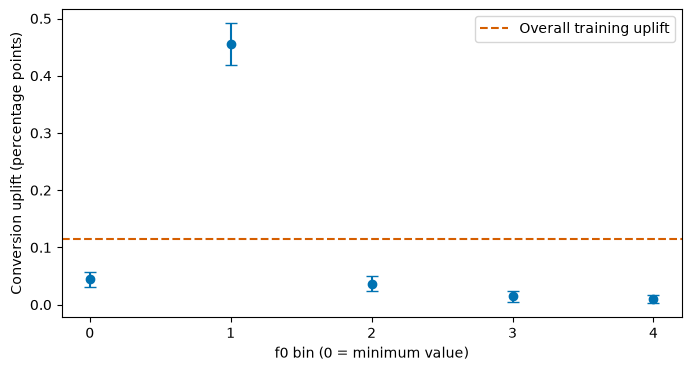

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(
    f0_uplift.index,
    f0_uplift["uplift_pp"],
    yerr=100 * f0_margin,
    fmt="o",
    color="#0072B2",
    capsize=4,
)
ax.axhline(training_uplift_pp, color="#D55E00", linestyle="--",
           label="Overall training uplift")
ax.set(
    xlabel="f0 bin (0 = minimum value)",
    ylabel="Conversion uplift (percentage points)",
    xticks=f0_uplift.index,
)
ax.legend()
plt.show()


In [21]:
def apply_f0_bins(rows, minimum, cut_edges):
    """Apply fixed training cutoffs and preserve the separate minimum-value bin."""
    return (pd.cut(rows["f0"], bins=cut_edges, labels=False) + 1).mask(
        rows["f0"].eq(minimum), 0
    )


In [22]:
def compare_validation_segments(val_f0, f0_uplift):
    """Evaluate the fixed training bins on validation rows."""
    val_counts = (
        val_f0.groupby(["f0_bin", "treatment"])["conversion"]
        .agg(users="size", conversions="sum")
        .unstack("treatment")
    )

    val_users = val_counts["users"]
    val_rates = val_counts["conversions"] / val_users
    val_uplift = val_rates[1] - val_rates[0]
    val_margin = CONFIDENCE_Z * np.sqrt(
        (val_rates * (1 - val_rates) / val_users).sum(axis=1)
    )

    comparison = pd.DataFrame({
        "train_uplift_pp": f0_uplift["uplift_pp"],
        "validation_uplift_pp": 100 * val_uplift,
        "validation_ci_low_pp": 100 * (val_uplift - val_margin),
        "validation_ci_high_pp": 100 * (val_uplift + val_margin),
    })
    return comparison


In [23]:
val_f0 = pd.read_parquet(SPLITS_DIR / "validation", columns=["f0", "treatment", "conversion"])
val_f0["f0_bin"] = apply_f0_bins(val_f0, f0_minimum, cut_edges)
comparison = compare_validation_segments(val_f0, f0_uplift)
display(comparison.round(4))


,train_uplift_pp,validation_uplift_pp,validation_ci_low_pp,validation_ci_high_pp
f0_bin,,,,
0,0.0441,0.0353,0.0060,0.0646
1,0.4548,0.4389,0.3603,0.5176
2,0.0369,0.0445,0.0153,0.0737
3,0.0146,0.0257,0.0074,0.0441
4,0.0095,-0.0003,-0.0174,0.0167


## 5. Uplift modeling

Fit the same two logistic regressions: scaled continuous features, one-hot
categorical encoding with minimum frequency 100, and `max_iter=500`. Use every
control training row and the same seeded 20% campaign sample. The T-learner
score is campaign conversion probability minus control conversion probability.

In [24]:
def build_conversion_model():
    """Build the original preprocessing and logistic regression pipeline."""
    preprocessing = ColumnTransformer([
        ("continuous", StandardScaler(), CONTINUOUS_FEATURES),
        ("categorical", OneHotEncoder(
            min_frequency=MIN_CATEGORY_FREQUENCY,
            handle_unknown="infrequent_if_exist",
        ), CATEGORICAL_FEATURES),
    ])

    model = make_pipeline(preprocessing, LogisticRegression(max_iter=LOGISTIC_MAX_ITER))
    return model


In [25]:
def fit_treatment_models(train_files):
    """Fit both arms with the original partition order and sampling draws."""
    rng = np.random.default_rng(RANDOM_SEED)
    models = {}

    for arm, keep_fraction in TRAIN_ARM_KEEP_FRACTIONS:
        parts = []

        for file in train_files:
            chunk = pd.read_parquet(
                file, columns=MODEL_FEATURES + ["treatment", "conversion"]
            )
            arm_rows = chunk.loc[chunk["treatment"].eq(arm)]

            if keep_fraction < 1:
                arm_rows = arm_rows.loc[rng.random(len(arm_rows)) < keep_fraction]

            parts.append(arm_rows)

        train_arm = pd.concat(parts, ignore_index=True)

        model = build_conversion_model()
        model.fit(train_arm[MODEL_FEATURES], train_arm["conversion"])
        models[arm] = model

        print(
            f"Arm {arm}: {len(train_arm):,} training rows, "
            f"{train_arm['conversion'].sum():,} conversions"
        )
        del train_arm, parts
    return models


In [26]:
train_files = sorted((SPLITS_DIR / "train").glob("part-*.parquet"))
models = fit_treatment_models(train_files)


Arm 0: 1,467,803 training rows, 2,829 conversions
Arm 1: 1,663,355 training rows, 5,239 conversions


In [27]:
def predict_conversion_probabilities(models, rows):
    """Predict each arm in fixed-size batches while preserving row alignment."""
    control_probabilities = np.empty(len(rows))
    campaign_probabilities = np.empty(len(rows))
    for start in range(0, len(rows), PREDICTION_BATCH_SIZE):
        stop = min(start + PREDICTION_BATCH_SIZE, len(rows))
        features = rows.iloc[start:stop][MODEL_FEATURES]
        control_probabilities[start:stop] = models[0].predict_proba(features)[:, 1]
        campaign_probabilities[start:stop] = models[1].predict_proba(features)[:, 1]
    return control_probabilities, campaign_probabilities


## 6. Evaluation and plots

### Shared audience selection and scoring

Each split gets a fresh seed-42 permutation. Stable sorting preserves that
permutation when scores tie. Metrics retain the original arm-specific rate
difference and the selected audience's size.

In [28]:
def rank_scores(scores, random_order):
    """Rank descending, breaking ties with the split's seeded permutation."""
    ranked = np.argsort(-scores[random_order], kind="stable")
    return random_order[ranked]


def prioritize_f0_bin(bin_values, random_order):
    """Move the strongest training bin first without changing within-bin order."""
    in_priority_bin = bin_values.to_numpy()[random_order] == PRIORITY_F0_BIN
    return np.concatenate([random_order[in_priority_bin], random_order[~in_priority_bin]])


def evaluate_audience(audience):
    by_arm = audience.groupby("treatment")["conversion"].agg(
        users="size", rate="mean"
    )
    uplift = by_arm.loc[1, "rate"] - by_arm.loc[0, "rate"]

    return {
        "selected_users": len(audience),
        "control_users": by_arm.loc[0, "users"],
        "campaign_users": by_arm.loc[1, "users"],
        "extra_conversions_per_1000_targeted": 1_000 * uplift,
        "estimated_extra_conversions": len(audience) * uplift,
    }


def evaluate_policies(rows, orders, audience_size):
    """Evaluate each fixed policy at the same audience size."""
    return pd.DataFrame(
        [evaluate_audience(rows.iloc[order[:audience_size]]) for order in orders.values()],
        index=orders.keys(),
    )


### Validation baselines and model rankings

In [29]:
target_size = int(TARGET_AUDIENCE_SHARE * len(val_f0))
random_order = np.random.default_rng(RANDOM_SEED).permutation(len(val_f0))
f0_order = prioritize_f0_bin(val_f0["f0_bin"], random_order)
validation_baseline_orders = {"Random": random_order, "Prioritize f0 bin 1": f0_order}
policy_results = evaluate_policies(val_f0, validation_baseline_orders, target_size)
display(policy_results.round(2))


,selected_users,control_users,campaign_users,extra_conversions_per_1000_targeted,estimated_extra_conversions
Random,209632,31218,178414,1.03,216.14
Prioritize f0 bin 1,209632,29447,180185,4.69,982.73


In [30]:
validation = pd.read_parquet(
    SPLITS_DIR / "validation", columns=MODEL_FEATURES + ["treatment", "conversion"]
)
alignment_columns = ["f0", "treatment", "conversion"]
if not validation[alignment_columns].equals(val_f0[alignment_columns]):
    raise ValueError("Validation row order differs from the baseline table.")

val_control_prob, val_campaign_prob = predict_conversion_probabilities(models, validation)
val_uplift_score = val_campaign_prob - val_control_prob
policy_orders = {
    **validation_baseline_orders,
    "Predicted conversion": rank_scores(val_campaign_prob, random_order),
    "Logistic T-learner": rank_scores(val_uplift_score, random_order),
}
validation_results = evaluate_policies(val_f0, policy_orders, target_size)
display(validation_results.round(2))


,selected_users,control_users,campaign_users,extra_conversions_per_1000_targeted,estimated_extra_conversions
Random,209632,31218,178414,1.03,216.14
Prioritize f0 bin 1,209632,29447,180185,4.69,982.73
Predicted conversion,209632,29004,180628,7.79,1633.55
Logistic T-learner,209632,28802,180830,7.12,1492.63


### Test evaluation with fixed models and policies

In [31]:
test = pd.read_parquet(
    SPLITS_DIR / "test", columns=MODEL_FEATURES + ["treatment", "conversion"]
)
test_target_size = int(TARGET_AUDIENCE_SHARE * len(test))
test_random_order = np.random.default_rng(RANDOM_SEED).permutation(len(test))
test_bins = apply_f0_bins(test, f0_minimum, cut_edges)
test_f0_order = prioritize_f0_bin(test_bins, test_random_order)
test_control_prob, test_campaign_prob = predict_conversion_probabilities(models, test)
test_uplift_score = test_campaign_prob - test_control_prob

test_orders = {
    "Random": test_random_order,
    "Prioritize f0 bin 1": test_f0_order,
    "Predicted conversion": rank_scores(test_campaign_prob, test_random_order),
    "Logistic T-learner": rank_scores(test_uplift_score, test_random_order),
}
test_results = evaluate_policies(test, test_orders, test_target_size)
display(test_results.round(2))


,selected_users,control_users,campaign_users,extra_conversions_per_1000_targeted,estimated_extra_conversions
Random,209776,31439,178337,1.42,297.25
Prioritize f0 bin 1,209776,29530,180246,5.79,1214.24
Predicted conversion,209776,28980,180796,8.67,1819.54
Logistic T-learner,209776,28803,180973,7.17,1503.69


### Paired bootstrap uncertainty

Preserve policy overlap using the original 16-category membership/arm/outcome encoding.

In [32]:
def uplift_per_1000(arm_counts):
    rates = arm_counts[..., 1] / arm_counts.sum(axis=-1)
    return 1_000 * (rates[..., 1] - rates[..., 0])

def policy_gap(counts):
    conversion_policy = counts[..., 1, :, :] + counts[..., 3, :, :]
    uplift_policy = counts[..., 2, :, :] + counts[..., 3, :, :]
    return uplift_per_1000(conversion_policy) - uplift_per_1000(uplift_policy)

def bootstrap_policy_gap(test, test_orders, test_target_size):
    """Bootstrap the fixed-policy gap with 5,000 paired multinomial draws."""
    # Membership codes: 0 = neither, 1 = conversion only,
    # 2 = T-learner only, 3 = both.
    membership = np.zeros(len(test), dtype=np.uint8)
    membership[test_orders["Predicted conversion"][:test_target_size]] |= 1
    membership[test_orders["Logistic T-learner"][:test_target_size]] |= 2

    treatment = test["treatment"].to_numpy(dtype=np.uint8)
    conversion = test["conversion"].to_numpy(dtype=np.uint8)

    pattern = 4 * membership + 2 * treatment + conversion
    pattern_counts = np.bincount(pattern, minlength=16)

    observed = pattern_counts.reshape(4, 2, 2)
    bootstrap = np.random.default_rng(RANDOM_SEED).multinomial(
        len(test), pattern_counts / len(test), size=BOOTSTRAP_REPLICATES
    ).reshape(-1, 4, 2, 2)

    gap = policy_gap(observed)
    low, high = np.quantile(policy_gap(bootstrap), BOOTSTRAP_QUANTILES)
    return gap, low, high


In [33]:
policy_gap_estimate, policy_gap_low, policy_gap_high = bootstrap_policy_gap(test, test_orders, test_target_size)
print(f"Gap per 1,000 targeted: {policy_gap_estimate:+.2f}")
print(f"95% paired bootstrap CI: [{policy_gap_low:+.2f}, {policy_gap_high:+.2f}]")


Gap per 1,000 targeted: +1.51
95% paired bootstrap CI: [+0.76, +2.20]


### Audience overlap and calibration diagnostics

In [34]:
def summarize_audience(rows, positions):
    rows = rows.iloc[positions]
    rates = 1_000 * rows.groupby("treatment")["conversion"].mean().reindex([0, 1])

    return {
        "users": len(rows),
        "control_per_1000": rates[0],
        "campaign_per_1000": rates[1],
        "uplift_per_1000": rates[1] - rates[0],
    }


In [35]:
conversion_idx = test_orders["Predicted conversion"][:test_target_size]
uplift_idx = test_orders["Logistic T-learner"][:test_target_size]

shared_idx = np.intersect1d(conversion_idx, uplift_idx)
conversion_only = np.setdiff1d(conversion_idx, uplift_idx)
uplift_only = np.setdiff1d(uplift_idx, conversion_idx)

policies = pd.DataFrame.from_dict({
    "Predicted conversion": summarize_audience(test, conversion_idx),
    "Logistic T-learner": summarize_audience(test, uplift_idx),
}, orient="index")

gap = policies.loc["Predicted conversion"] - policies.loc["Logistic T-learner"]

display(policies.round(2))
print(f"Campaign-rate contribution: {gap['campaign_per_1000']:+.2f}")
print(f"Control-rate contribution: {-gap['control_per_1000']:+.2f}")
print(f"Net uplift gap: {gap['uplift_per_1000']:+.2f}")

print(f"\nOverlap: {len(shared_idx):,} users ({len(shared_idx) / test_target_size:.1%})")

display(pd.DataFrame.from_dict({
    "Selected by both": summarize_audience(test, shared_idx),
    "Predicted conversion only": summarize_audience(test, conversion_only),
    "T-learner only": summarize_audience(test, uplift_only),
}, orient="index").round(2))


Campaign-rate contribution: +3.75
Control-rate contribution: -2.25
Net uplift gap: +1.51

Overlap: 164,273 users (78.3%)


,users,control_per_1000,campaign_per_1000,uplift_per_1000
Predicted conversion,209776,18.77,27.45,8.67
Logistic T-learner,209776,16.53,23.69,7.17


,users,control_per_1000,campaign_per_1000,uplift_per_1000
Selected by both,164273,20.77,29.56,8.79
Predicted conversion only,45503,12.05,19.71,7.66
T-learner only,45503,1.86,2.36,0.50


In [36]:
def diagnose_segment_calibration(test, segments, test_campaign_prob, test_uplift_score):
    """Compare predicted and observed probabilities within selected segments."""
    treatment = test["treatment"].to_numpy()
    conversion = test["conversion"].to_numpy()

    # Recover the control probability from uplift = campaign - control.
    probabilities = {
        0: test_campaign_prob - test_uplift_score,
        1: test_campaign_prob,
    }

    ranking_rows = []
    calibration_rows = []

    for segment, positions in segments.items():
        ranking_rows.append({
            "segment": segment,
            "predicted_control_per_1000": 1_000 * probabilities[0][positions].mean(),
            "predicted_campaign_per_1000": 1_000 * probabilities[1][positions].mean(),
            "predicted_uplift_per_1000": 1_000 * test_uplift_score[positions].mean(),
        })

        for arm, label in [(0, "Control"), (1, "Campaign")]:
            in_arm = positions[treatment[positions] == arm]
            predicted = 1_000 * probabilities[arm][in_arm].mean()
            observed = 1_000 * conversion[in_arm].mean()

            calibration_rows.append({
                "segment": segment,
                "arm": label,
                "users": len(in_arm),
                "conversions": conversion[in_arm].sum(),
                "predicted_per_1000": predicted,
                "observed_per_1000": observed,
                "error_per_1000": predicted - observed,
            })

    ranking = pd.DataFrame(ranking_rows).set_index("segment")
    calibration = pd.DataFrame(calibration_rows).set_index(["segment", "arm"])
    return ranking, calibration


In [37]:
segments = {
    "Selected by both": shared_idx,
    "Predicted conversion only": conversion_only,
    "T-learner only": uplift_only,
}
ranking, calibration = diagnose_segment_calibration(test, segments, test_campaign_prob, test_uplift_score)
display(ranking.round(2))
display(calibration.round(2))


,predicted_control_per_1000,predicted_campaign_per_1000,predicted_uplift_per_1000
segment,,,
Selected by both,16.51,30.33,13.82
Predicted conversion only,19.14,15.90,-3.24
T-learner only,0.54,2.17,1.63


users  ...  error_per_1000
segment                   arm               ...                
Selected by both          Control    22339  ...           -3.92
                          Campaign  141934  ...            0.70
Predicted conversion only Control     6641  ...            6.83
                          Campaign   38862  ...           -3.77
T-learner only            Control     6464  ...           -1.31
                          Campaign   39039  ...           -0.18

[6 rows x 5 columns]

### Validation uplift across audience sizes

Reuse the validation probabilities from the unchanged fitted models. The
assertion checks that the 10% point equals the earlier validation comparison.

In [38]:
def evaluate_audience_sizes(rows_to_score, policy_orders, audience_shares):
    """Evaluate fixed policy rankings over the configured audience shares."""
    rows = []

    for policy, order in policy_orders.items():
        for budget in audience_shares:
            audience_size = int(budget * len(rows_to_score))
            audience = rows_to_score.iloc[order[:audience_size]]
            rows.append({
                "policy": policy,
                "audience_share": budget,
                POLICY_METRIC: evaluate_audience(audience)[POLICY_METRIC],
            })

    chart_data = pd.DataFrame(rows).pivot(
        index="audience_share", columns="policy", values=POLICY_METRIC
    )
    return chart_data


In [39]:
chart_data = evaluate_audience_sizes(val_f0, policy_orders, AUDIENCE_SHARES)
np.testing.assert_allclose(
    chart_data.loc[TARGET_AUDIENCE_SHARE, validation_results.index].to_numpy(),
    validation_results[POLICY_METRIC].to_numpy(),
)


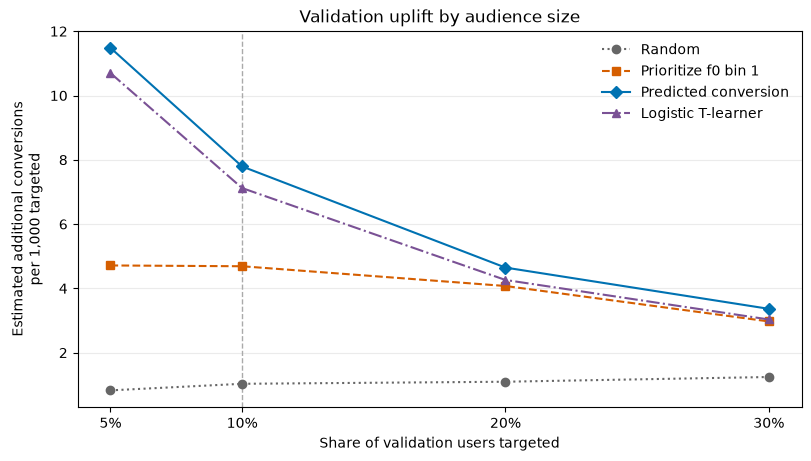

In [40]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")

for policy, (color, marker, linestyle) in POLICY_STYLES.items():
    ax.plot(
        chart_data.index, chart_data[policy],
        color=color, marker=marker, linestyle=linestyle, label=policy,
    )

ax.axvline(TARGET_AUDIENCE_SHARE, color="#AAAAAA", linewidth=1, linestyle="--", zorder=0)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set(
    title="Validation uplift by audience size",
    xlabel="Share of validation users targeted",
    ylabel="Estimated additional conversions\nper 1,000 targeted",
    xticks=AUDIENCE_SHARES,
)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

fig.savefig(FIGURES_DIR / "validation_uplift_by_audience_size.png", dpi=200)
plt.show()


## 7. Takeaways

- Campaign conversion rates exceed control rates, with overall uplift of +0.1152
  percentage points. Two-group `f3` standardization reduces this to +0.1060.
- Uplift is concentrated. The strongest `f0` bin repeats in validation, while the
  highest bin has no clear validation benefit.
- Conversion-probability ranking is the strongest tested baseline on validation
  and test data. The logistic T-learner's calibration errors distort its ranking.
- Per-user gains decline as the targeted audience grows. No cost or conversion
  value data is available to establish an optimal profitable audience size.
- Test diagnostics are exploratory. Further tuning based on them needs a fresh
  holdout. The bootstrap covers evaluation uncertainty for fixed fitted models,
  not training or model-selection uncertainty.